In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

PROJECT_DATA_ROOT = Path('../..').resolve() / "01_data"
ACTUAL_LOAD = PROJECT_DATA_ROOT / "2_cleaned/load/total_load_20201231_20260526.csv"
LOAD_FORECAST = PROJECT_DATA_ROOT / "1.2_raw_api/load_fcast_wzn_archive_20230801_20230831.parquet"
RTM_PRICE = PROJECT_DATA_ROOT / "2_cleaned" / "rtm_price" / "rtm_price_aggregated_2021_2025.csv"
OUT_DIR = PROJECT_DATA_ROOT / "3_analysis" / "load_forecast" / "Aug 2023 Case Study"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df_rtm = pd.read_csv(RTM_PRICE)
df_forecast = pd.read_parquet(LOAD_FORECAST)
df_load = pd.read_csv(ACTUAL_LOAD)

### Identify Forecast Lead Time: 3 hour, 6 hour, and day-ahead

In [3]:
df_forecast.dtypes

deliveryDate              object
hourEnding                object
systemTotal              float64
DSTFlag                  boolean
postedDatetime    datetime64[us]
dtype: object

In [4]:
## tect block
con = duckdb.connect()
df_test = con.execute("""
    SELECT 
                    deliveryDate
                    ,systemTotal AS load_pred
                    ,STR_SPLIT(hourEnding, ':')[1]::INTEGER AS delivery_hr
                    ,EXTRACT('hour' FROM postedDatetime) AS posted_hr
                    ,DATE_DIFF('day', strptime(deliveryDate, '%Y-%m-%d'), postedDatetime) AS day_diff
            FROM df_forecast;
""").fetchdf()
df_test.dtypes

deliveryDate     object
load_pred       float64
delivery_hr       int32
posted_hr         int64
day_diff          int64
dtype: object

In [5]:
con = duckdb.connect()
df_lag = con.execute("""
   WITH 
        df_hours AS (
        SELECT 
                deliveryDate
                ,postedDatetime
                ,systemTotal AS load_pred
                ,STR_SPLIT(hourEnding, ':')[1]::INTEGER AS delivery_hr
                ,EXTRACT('hour' FROM postedDatetime) AS posted_hr
                ,DATE_DIFF('day', strptime(deliveryDate, '%Y-%m-%d'), postedDatetime) AS day_diff
        FROM df_forecast
        ),

        df_lag AS (
        SELECT
                CONCAT(deliveryDate,' ',delivery_hr,':00')::DATETIME AS datetime
                ,postedDatetime
                ,load_pred
                ,CASE 
                        WHEN day_diff = 0 THEN (delivery_hr - posted_hr)
                        WHEN day_diff = -1 THEN (delivery_hr - posted_hr + 24)
                        ELSE null
                 END AS lead_time
        FROM df_hours
        )
   SELECT *
   FROM df_lag
   WHERE lead_time <= 24 AND lead_time >=0
   ORDER BY datetime;
""").fetchdf()

df_lag.dtypes

datetime          datetime64[us]
postedDatetime    datetime64[us]
load_pred                float64
lead_time                  int64
dtype: object

In [6]:
df_lag

,datetime,postedDatetime,load_pred,lead_time
0,2023-08-01 01:00:00,2023-07-31 01:30:00,62768.7578,24
1,2023-08-01 01:00:00,2023-07-31 02:30:00,62677.8854,23
2,2023-08-01 01:00:00,2023-07-31 03:30:00,62538.6462,22
3,2023-08-01 01:00:00,2023-07-31 04:30:00,62557.7479,21
4,2023-08-01 01:00:00,2023-07-31 05:30:00,62585.4027,20
...,...,...,...,...
18564,2023-09-01 00:00:00,2023-08-31 05:30:01,58912.3510,19
18565,2023-09-01 00:00:00,2023-08-31 04:30:03,58410.3202,20
18566,2023-09-01 00:00:00,2023-08-31 03:30:00,58519.3301,21
18567,2023-09-01 00:00:00,2023-08-31 02:30:00,58612.5286,22


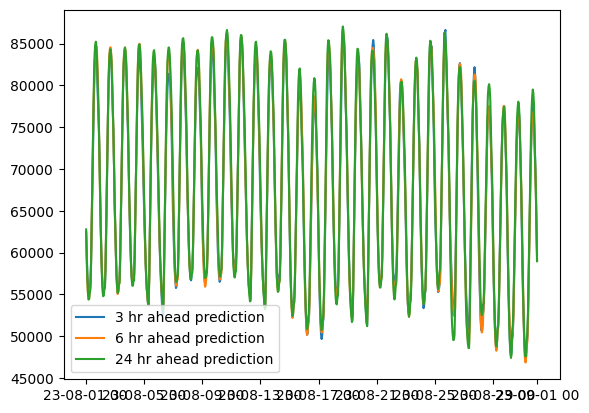

In [7]:
import matplotlib.dates as mdates
myFmt = mdates.DateFormatter('%y-%m-%d %H')
plt.gca().xaxis.set_major_formatter(myFmt)

for lag in [3, 6, 24]:
    df = df_lag[df_lag['lead_time'] == lag]
    plt.plot(df['datetime'], df['load_pred'], label=f'{lag} hr ahead prediction') 
plt.legend()

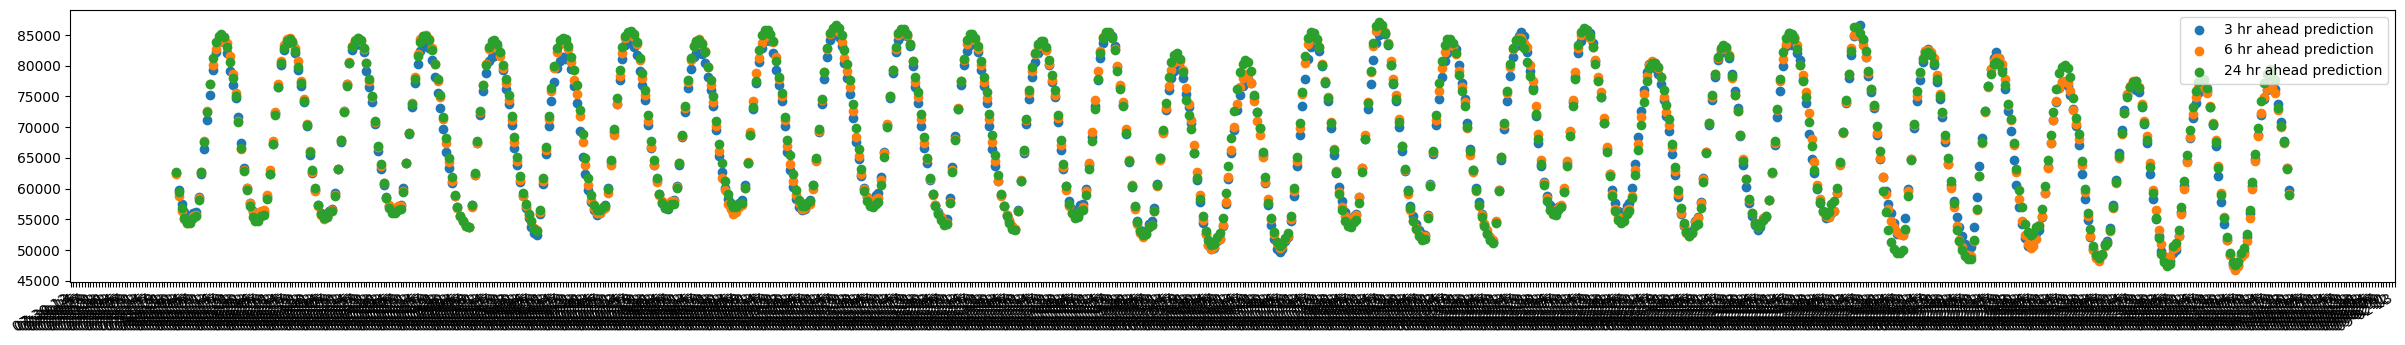

In [8]:
fig, ax = plt.subplots(figsize=(30, 4))

# Plot your data (assuming x is a list of datetime objects)
for lag in [3, 6, 24]:
    df = df_lag[df_lag['lead_time'] == lag]
    ax.scatter(df['datetime'], df['load_pred'], label=f'{lag} hr ahead prediction') 
plt.legend()

# Set tick frequency to every hour
ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))

# Make labels look neat
fig.autofmt_xdate()
plt.show()


### forecast error

In [9]:
# Merge df_lag with actual load to compare predictions vs actuals
df_lag['datetime'] = pd.to_datetime(df_lag['datetime'])
df_load['datetime'] = pd.to_datetime(df_load['datetime'])
df_rtm['date_time'] = pd.to_datetime(df_rtm['date_time'])

df_comparison = df_lag.merge(df_load, on='datetime', how='inner')
df_comparison = df_comparison.merge(df_rtm, left_on='datetime', right_on='date_time')
df_comparison = df_comparison.filter(['datetime', 'load_pred', 'total_load', 'avg_rtm_price', 'lead_time'])
df_comparison

,datetime,load_pred,total_load,avg_rtm_price,lead_time
0,2023-08-01 01:00:00,62768.7578,63356.77,22.114333,24
1,2023-08-01 01:00:00,62677.8854,63356.77,22.114333,23
2,2023-08-01 01:00:00,62538.6462,63356.77,22.114333,22
3,2023-08-01 01:00:00,62557.7479,63356.77,22.114333,21
4,2023-08-01 01:00:00,62585.4027,63356.77,22.114333,20
...,...,...,...,...,...
18564,2023-09-01 00:00:00,58912.3510,59653.06,22.824167,19
18565,2023-09-01 00:00:00,58410.3202,59653.06,22.824167,20
18566,2023-09-01 00:00:00,58519.3301,59653.06,22.824167,21
18567,2023-09-01 00:00:00,58612.5286,59653.06,22.824167,22


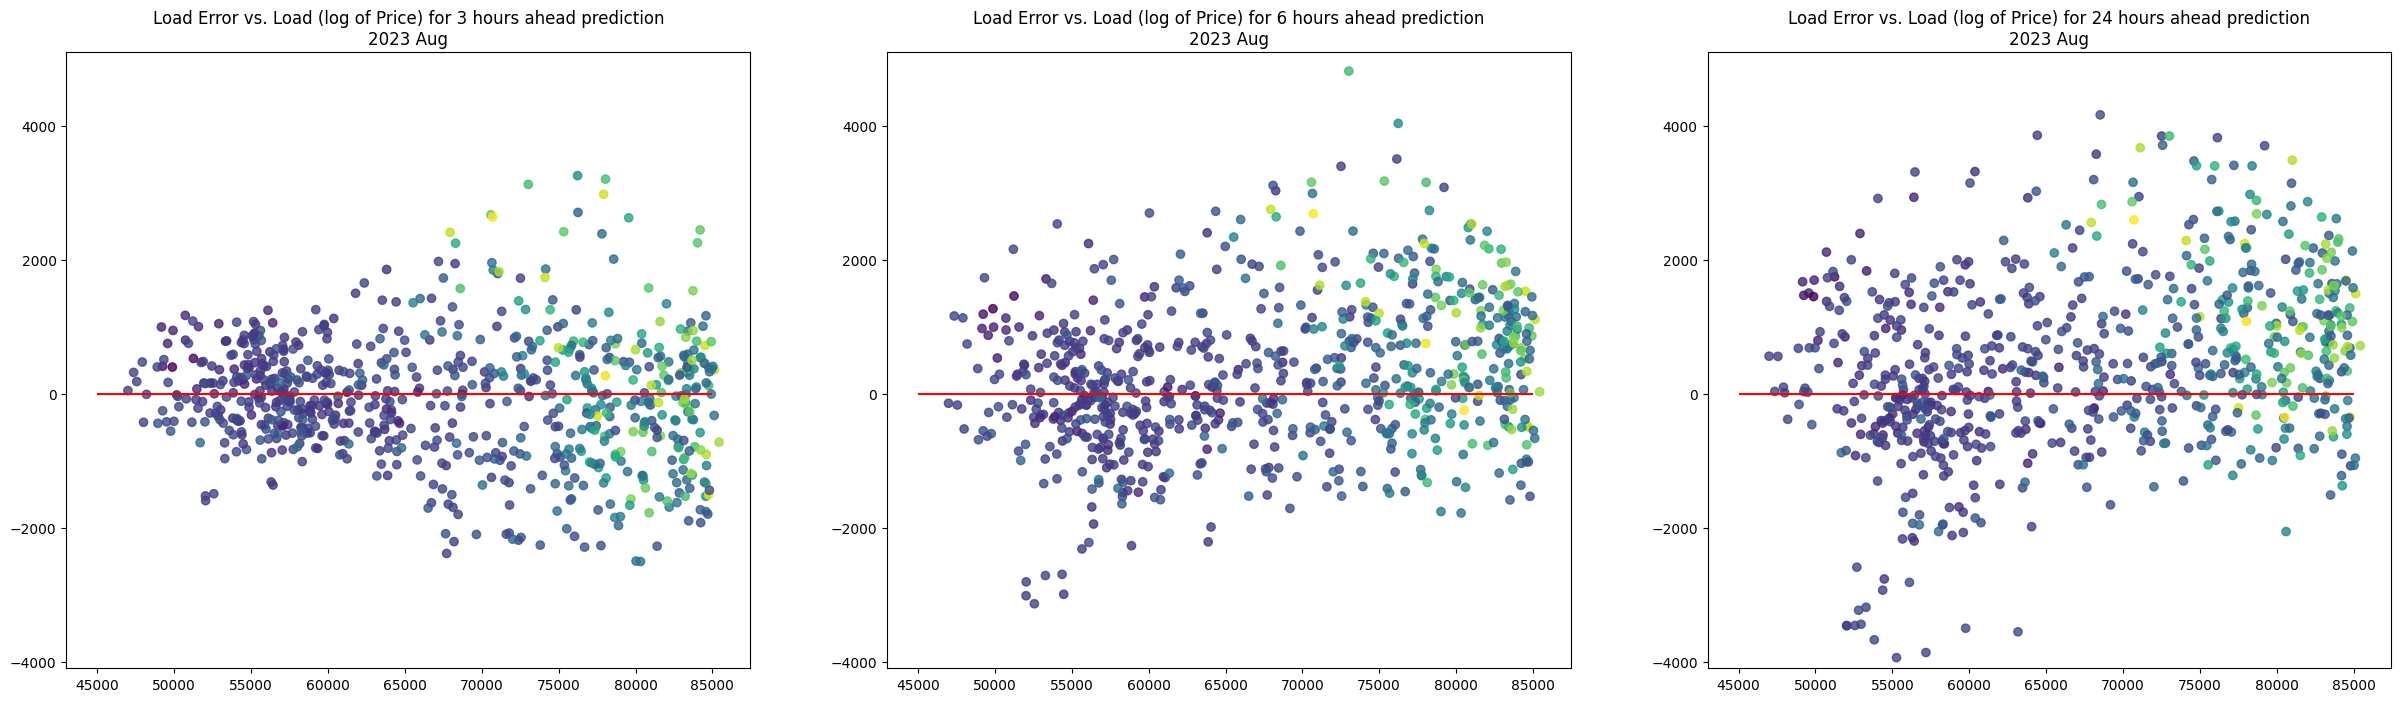

In [10]:
# plot error vs. actual load
fig, axes = plt.subplots(1, 3, figsize=(30, 8))

for lag, ax in zip([3, 6, 24], axes.flat):
    df_lag = df_comparison[df_comparison['lead_time'] == lag]
    ax.scatter(df_lag['total_load'], df_lag['load_pred'] - df_lag['total_load'], alpha=0.8, c=np.log(df_lag['avg_rtm_price']))
    ax.set_title(f'Load Error vs. Load (log of Price) for {lag} hours ahead prediction\n2023 Aug')
    ax.hlines(0, 45000, 85000, colors='red')
    ax.set_ylim(-4100, 5100)

In [101]:
# plot how median change overtime for different lead times

df_comparison['hour'] = df_comparison['datetime'].dt.hour
df_comparison['pred_error'] = df_comparison['load_pred'] - df_comparison['total_load']
df_comparison.to_csv(OUT_DIR / 'load prediction varied by lead time 202308.csv')
df_comparison.head()

,datetime,load_pred,total_load,avg_rtm_price,lead_time,hour,pred_error
0,2023-08-01 01:00:00,62768.7578,63356.77,22.114333,24,1,-588.0122
1,2023-08-01 01:00:00,62677.8854,63356.77,22.114333,23,1,-678.8846
2,2023-08-01 01:00:00,62538.6462,63356.77,22.114333,22,1,-818.1238
3,2023-08-01 01:00:00,62557.7479,63356.77,22.114333,21,1,-799.0221
4,2023-08-01 01:00:00,62585.4027,63356.77,22.114333,20,1,-771.3673


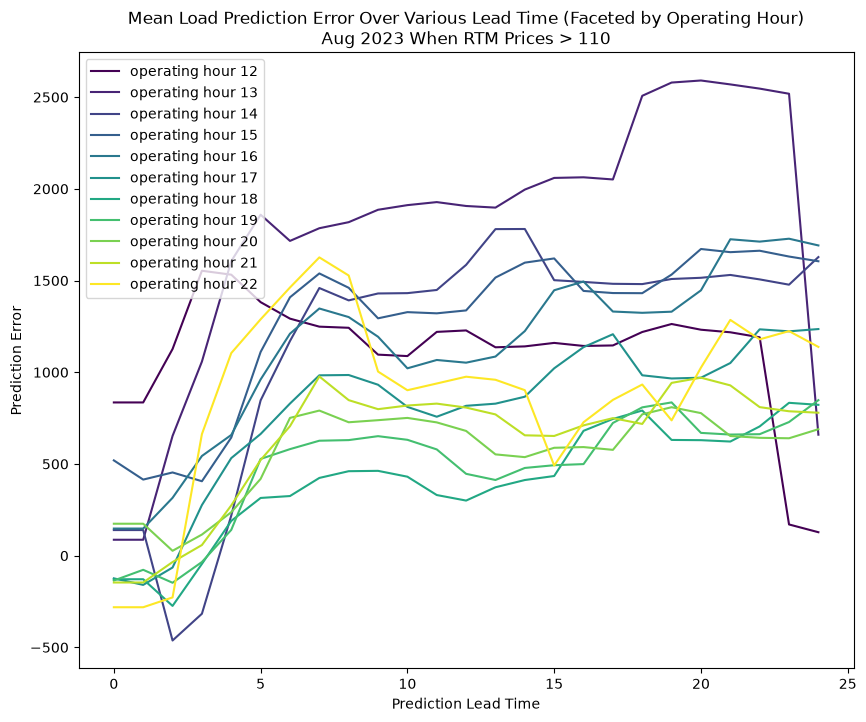

In [99]:
# filter rtm_price > threshold
# groupby lead_time
# take median of load prediction error
# plot

threshold = 110
df_extreme = df_comparison[df_comparison['avg_rtm_price'] > threshold]

df_pred_error = df_extreme.groupby(['lead_time', 'hour']).agg(
    mean_error = ('pred_error', 'mean'),
    median_error = ('pred_error', 'median')
).reset_index()

num_plots = len(df_pred_error['hour'].unique())
colors = plt.cm.viridis(np.linspace(0, 1, num_plots))
plt.subplots(figsize=(10, 8))

for i, hour in enumerate(df_pred_error['hour'].unique()):
    df_hour = df_pred_error[df_pred_error['hour'] == hour]
    plt.plot(df_hour['lead_time'], df_hour['mean_error'], color=colors[i], label=f'operating hour {hour}')

plt.title(f'Mean Load Prediction Error Over Various Lead Time (Faceted by Operating Hour)\nAug 2023 When RTM Prices > {threshold}')
plt.ylabel('Prediction Error')
plt.xlabel('Prediction Lead Time')
plt.legend()
plt.savefig(OUT_DIR / f'Mean Load Prediction Error Over Various Lead Time for RTM Prices > {threshold}')
plt.show()